In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import seaborn as sns
import importlib
import bcifswsni_bn
importlib.reload(bcifswsni_bn)

from bcifswsni_bn import run_model
import nibabel as nib


In [2]:
import nibabel as nib

img_3d = nib.load("brain.mnc").get_fdata()

In [3]:
slice_img = img_3d[:, :, 90]

In [4]:
seg, U, V, B = run_model(
    slice_img,
    c=3,              # CSF, GM, WM
    m=2,
    a_=0.5,           # spatial strength (tune later)
    g="yager",        # or "sugeno"
    e=1e-5,
    max_iter=50,
    p=2               # for yager
)

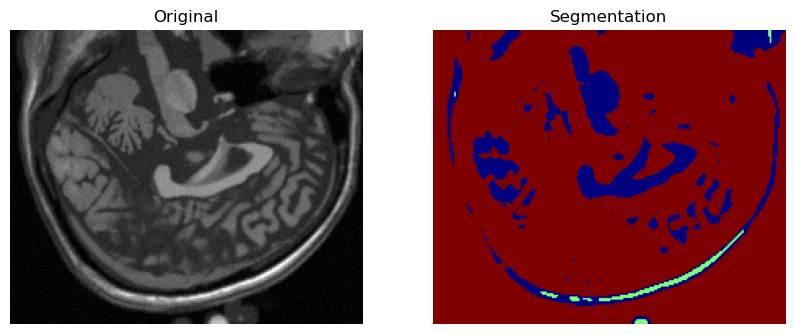

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(slice_img, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(seg, cmap='jet')
plt.title("Segmentation")
plt.axis('off')

plt.show()

(np.float64(-0.5), np.float64(216.5), np.float64(180.5), np.float64(-0.5))

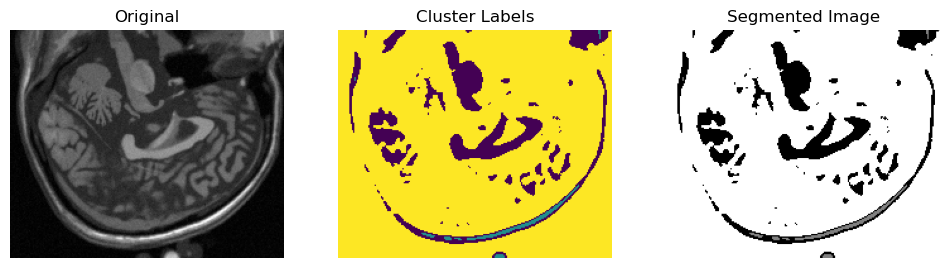

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(slice_img, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(seg, cmap='viridis')
plt.title("Cluster Labels")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(seg, cmap='gray')
plt.title("Segmented Image")
plt.axis('off')